# LAB 06 - Bài 19: Query thay đổi

**Mục tiêu:** Giữ nguyên sequence, thay đổi query và so sánh attention distribution.

- Query A đại diện cho hướng sentiment.
- Query B đại diện cho hướng topic/movie.
- Keys dưới đây là vector giả lập được thiết kế để minh họa hai hướng; đây không phải embedding được huấn luyện.

Quy trình: tính scaled dot-product scores, softmax ổn định, lập bảng token/score/attention cho cả hai query, và vẽ hai phân phối để quan sát sự thay đổi.

,Token,Score A,Attention A,Score B,Attention B
0,The,0.000000,0.091111,0.057735,0.090957
1,movie,0.115470,0.102263,0.577350,0.152933
2,was,0.000000,0.091111,0.057735,0.090957
3,surprisingly,0.202073,0.111514,0.115470,0.096363
4,good,0.577350,0.162297,0.028868,0.088368
5,despite,-0.028868,0.088518,0.057735,0.090957
6,a,0.000000,0.091111,0.000000,0.085854
7,very,0.057735,0.096526,0.000000,0.085854
8,slow,-0.202073,0.074441,0.115470,0.096363
9,beginning,0.000000,0.091111,0.346410,0.121396


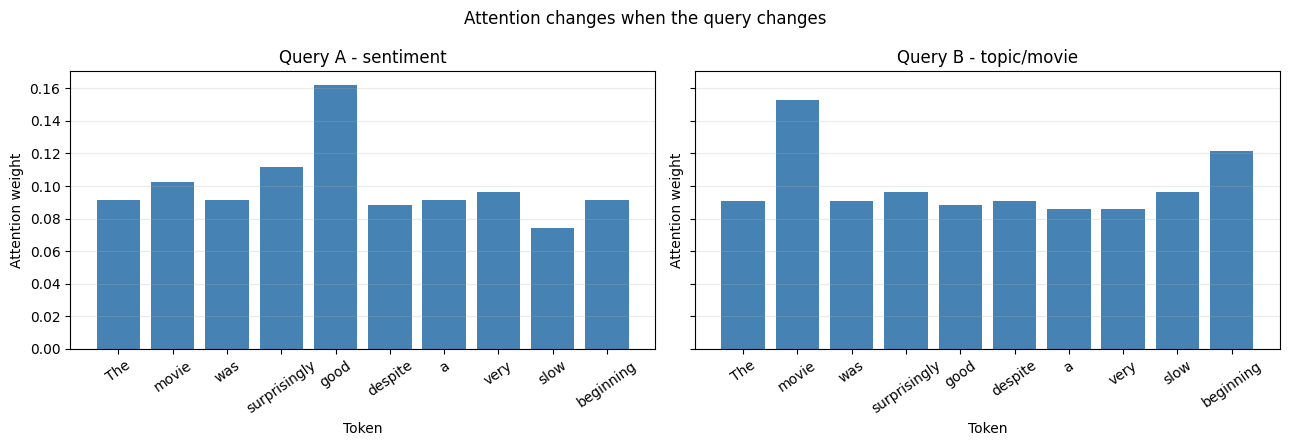

Top token for Query A: good
Top token for Query B: movie
Sum of weights A/B: 1.000000 / 1.000000
Mean absolute weight change: 0.021063


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Same token sequence as Experiment 1
tokens = [
    "The", "movie", "was", "surprisingly", "good",
    "despite", "a", "very", "slow", "beginning"
]

# Simulated key features: [sentiment, movie-topic, intensity/adverb]
# These illustrative vectors are not learned embeddings.
keys = np.array([
    [0.00, 0.10, 0.00],  # The
    [0.20, 1.00, 0.10],  # movie
    [0.00, 0.10, 0.00],  # was
    [0.35, 0.20, 0.80],  # surprisingly
    [1.00, 0.05, 0.20],  # good
    [-0.05, 0.10, 0.00], # despite
    [0.00, 0.00, 0.00],  # a
    [0.10, 0.00, 0.30],  # very
    [-0.35, 0.20, 0.85], # slow
    [0.00, 0.60, 0.10],  # beginning
], dtype=np.float64)

# Query A emphasizes sentiment; Query B emphasizes the movie topic.
queries = {
    "Query A - sentiment": np.array([1.0, 0.0, 0.0]),
    "Query B - topic/movie": np.array([0.0, 1.0, 0.0]),
}
d_k = keys.shape[1]

def stable_softmax(x):
    x = np.asarray(x, dtype=np.float64)
    shifted = x - np.max(x, axis=-1, keepdims=True)
    exp_x = np.exp(shifted)
    return exp_x / exp_x.sum(axis=-1, keepdims=True)

# Scaled dot-product scores and attention distributions
results = {}
for name, query in queries.items():
    scores = (keys @ query) / np.sqrt(d_k)
    results[name] = {"scores": scores, "weights": stable_softmax(scores)}

query_a, query_b = list(queries.keys())
weights_a = results[query_a]["weights"]
weights_b = results[query_b]["weights"]
results_table = pd.DataFrame({
    "Token": tokens,
    "Score A": results[query_a]["scores"],
    "Attention A": weights_a,
    "Score B": results[query_b]["scores"],
    "Attention B": weights_b,
})
display(results_table.round(6))

# Compare distributions for the same tokens
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, title, weights in [
    (axes[0], query_a, weights_a),
    (axes[1], query_b, weights_b),
]:
    ax.bar(tokens, weights, color="steelblue")
    ax.set_title(title)
    ax.set_xlabel("Token")
    ax.set_ylabel("Attention weight")
    ax.tick_params(axis="x", rotation=35)
    ax.grid(axis="y", alpha=0.25)
fig.suptitle("Attention changes when the query changes")
fig.tight_layout()
plt.show()

print(f"Top token for Query A: {tokens[int(np.argmax(weights_a))]}")
print(f"Top token for Query B: {tokens[int(np.argmax(weights_b))]}")
print(f"Sum of weights A/B: {weights_a.sum():.6f} / {weights_b.sum():.6f}")
print(f"Mean absolute weight change: {np.mean(np.abs(weights_a - weights_b)):.6f}")